# 05_02 The Central Limit Theorem: Why the Bell Curve Is Everywhere

**Learning objectives**
- State the **Central Limit Theorem** (CLT) for sums and for averages, and standardize correctly.
- See it **from any starting distribution**: skewed, bimodal, discrete, heavy-tailed, and understand why the Normal appears.
- Measure **how fast** it kicks in (the Berry-Esseen rate $1/\sqrt n$, driven by skewness) and test the folk rule "$n\ge30$".
- Use it for **probabilities of sums and averages**, for control limits and for confidence intervals, and know when it **fails** (infinite variance, heavy skew with moderate $n$).

**Prerequisites:** [05_01 Law of large numbers](05_01_law_of_large_numbers.ipynb), [02_01 Normal](../../module_02_continuous/notebooks/02_01_uniform_normal.ipynb), [04_02 Limits and approximations](../../module_04_relationships/notebooks/04_02_limits_and_approximations.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Mean and variance of a sum and an average** (independent, identical): $E[S_n]=n\mu$, $\mathrm{Var}(S_n)=n\sigma^2$, $E[\bar X_n]=\mu$, $\mathrm{Var}(\bar X_n)=\sigma^2/n$.
- **Standardizing** a variable: $Z=(Y-E[Y])/\mathrm{sd}(Y)$ has mean 0 and variance 1.
- **Moment generating function (MGF):** $M_X(t)=E[e^{tX}]$; the MGF of an independent sum is the product of the MGFs, and the MGF determines the distribution.
- **Skewness:** $\gamma=E[((X-\mu)/\sigma)^3]$; the Normal has $\gamma=0$.

## 3. Intuition and story

Roll one die: the outcome is uniform on 1 to 6, a flat histogram. Add **two** dice: a triangle. Add **ten**: already a bell. Heights of people, measurement errors, the total of 200 customers' orders, the average of 1,000 survey answers: the bell curve keeps appearing because these quantities are **sums of many small independent contributions**, and **the shape of a sum forgets the shape of its parts**: only the mean and variance of the parts survive.

That is the Central Limit Theorem. It explains why the Normal distribution is the default model for noise, and it is the engine behind almost all classical statistics: confidence intervals, z-tests, control charts, polls. The practical questions are the ones we answer with numbers: **how large must $n$ be?** and **what can go wrong?**

## 4. Formal definition

**CLT (Lindeberg-Lévy).** Let $X_1,X_2,\dots$ be iid with finite mean $\mu$ and finite variance $\sigma^2>0$. Then
$$Z_n=\frac{\sum_{i=1}^nX_i-n\mu}{\sigma\sqrt n}=\frac{\bar X_n-\mu}{\sigma/\sqrt n}\ \xrightarrow{d}\ N(0,1),$$
that is, $P(Z_n\le z)\to\Phi(z)$ for every $z$.

**In practice** (large $n$): $S_n\approx N(n\mu,\,n\sigma^2)$ and $\bar X_n\approx N(\mu,\,\sigma^2/n)$.

**Speed (Berry-Esseen).** $\sup_z|P(Z_n\le z)-\Phi(z)|\le\dfrac{0.4748\,\rho}{\sigma^3\sqrt n}$ with $\rho=E|X-\mu|^3$. The error shrinks like $1/\sqrt n$ and is proportional to the skewness-like ratio $\rho/\sigma^3$.

**First-order correction (Edgeworth).** $P(Z_n\le z)\approx\Phi(z)-\dfrac{\gamma}{6\sqrt n}(z^2-1)\varphi(z)$ with $\gamma$ the skewness of one observation.

## 5. Derivations

### 5.1 Why the Normal? The MGF argument
Standardize one observation: $Y_i=(X_i-\mu)/\sigma$ has mean 0, variance 1, and MGF $M(s)=1+\tfrac{s^2}{2}+\tfrac{\gamma s^3}{6}+o(s^3)$. Then $Z_n=\frac1{\sqrt n}\sum Y_i$ has MGF
$$M_{Z_n}(t)=\Big[M\big(t/\sqrt n\big)\Big]^n=\Big[1+\frac{t^2}{2n}+\frac{\gamma t^3}{6n^{3/2}}+\dots\Big]^n\ \longrightarrow\ e^{t^2/2},$$
the MGF of $N(0,1)$ (using $(1+a/n)^n\to e^a$). **In plain words.** After standardizing, every distribution looks like $1+t^2/2$ to second order; the first thing that depends on the original shape is the *skewness term*, and it is multiplied by $n^{-3/2}$, so it dies out faster than the variance term.

### 5.2 The speed: what the first leftover term says
Taking the logarithm: $\ln M_{Z_n}(t)=\dfrac{t^2}{2}+\dfrac{\gamma\,t^3}{6\sqrt n}+O(1/n)$. The leading error is the cubic term, of size $\gamma/\sqrt n$. So the error is about $\dfrac{|\gamma|}{\sqrt n}$ times a constant (Berry-Esseen gives a rigorous constant), which gives the three rules of thumb:
- symmetric parents ($\gamma=0$; Uniform, Normal, coin with $p=0.5$): the $n^{-1/2}$ term vanishes and the Normal is excellent already for $n\approx5$ to 10;
- moderately skewed parents (Exponential, $\gamma=2$): $n\approx30$ to 50;
- heavily skewed parents (Bernoulli(0.01), Lognormal with $\sigma=1.5$): hundreds to thousands.

### 5.3 Sums versus averages
$S_n=n\bar X_n$, so the CLT for the sum is the CLT for the average multiplied by $n$: $S_n\approx N(n\mu,n\sigma^2)$. The **sum** gets wider in absolute terms ($\sqrt n\,\sigma$) but narrower relative to its mean ($\sigma/(\mu\sqrt n)$).

### 5.4 Special cases you already know
- $X_i\sim\text{Bernoulli}(p)$: Binomial $\to$ Normal (04_02), with the continuity correction.
- $X_i\sim\text{Exponential}$: Gamma $\to$ Normal; $X_i\sim\text{Poisson}(\lambda)$: Poisson($n\lambda$) $\to$ Normal.
- $X_i\sim N$: the sum is exactly Normal for every $n$ (nothing to approximate).

### 5.5 When it fails
If $\sigma^2=\infty$ the CLT does not apply. For the Cauchy distribution the average is again Cauchy for every $n$ (05_01). For heavy-tailed parents with $1<\alpha\le2$ (Pareto) the sum, properly scaled by $n^{1/\alpha}$, converges to a **stable law**, not a Normal. And for finite-variance but very skewed parents the approximation exists but is **useless at moderate $n$** (Example 3).

## 6. Properties and relationships

- **Universality:** only $\mu$ and $\sigma^2$ of the parent matter in the limit.
- **Non-identical parents:** the CLT also holds when summands differ, as long as no single term dominates (Lindeberg and Lyapunov conditions): this is why measurement errors made of many small independent causes look Normal.
- **Delta method:** if $\bar X_n\approx N(\mu,\sigma^2/n)$ and $g$ is smooth, then $g(\bar X_n)\approx N\big(g(\mu),\,g'(\mu)^2\sigma^2/n\big)$. This gives the distribution of ratios, logs and square roots of averages.
- **Multivariate CLT:** vector averages are approximately multivariate Normal with covariance $\Sigma/n$ (03_01).
- **Link to the LLN (05_01):** the LLN says $\bar X_n\to\mu$; the CLT says the leftover error $\bar X_n-\mu$ is of size $\sigma/\sqrt n$ and Normal in shape.

## 7. 2D visuals

### 7.1 The recipe on six very different parents
Rows: parents. Columns: the sample size $n$. Each histogram shows 20,000 standardized sample means; the black curve is $N(0,1)$. Flat, skewed, two-humped and spiky parents all become bell-shaped; the skewed ones just need more $n$.

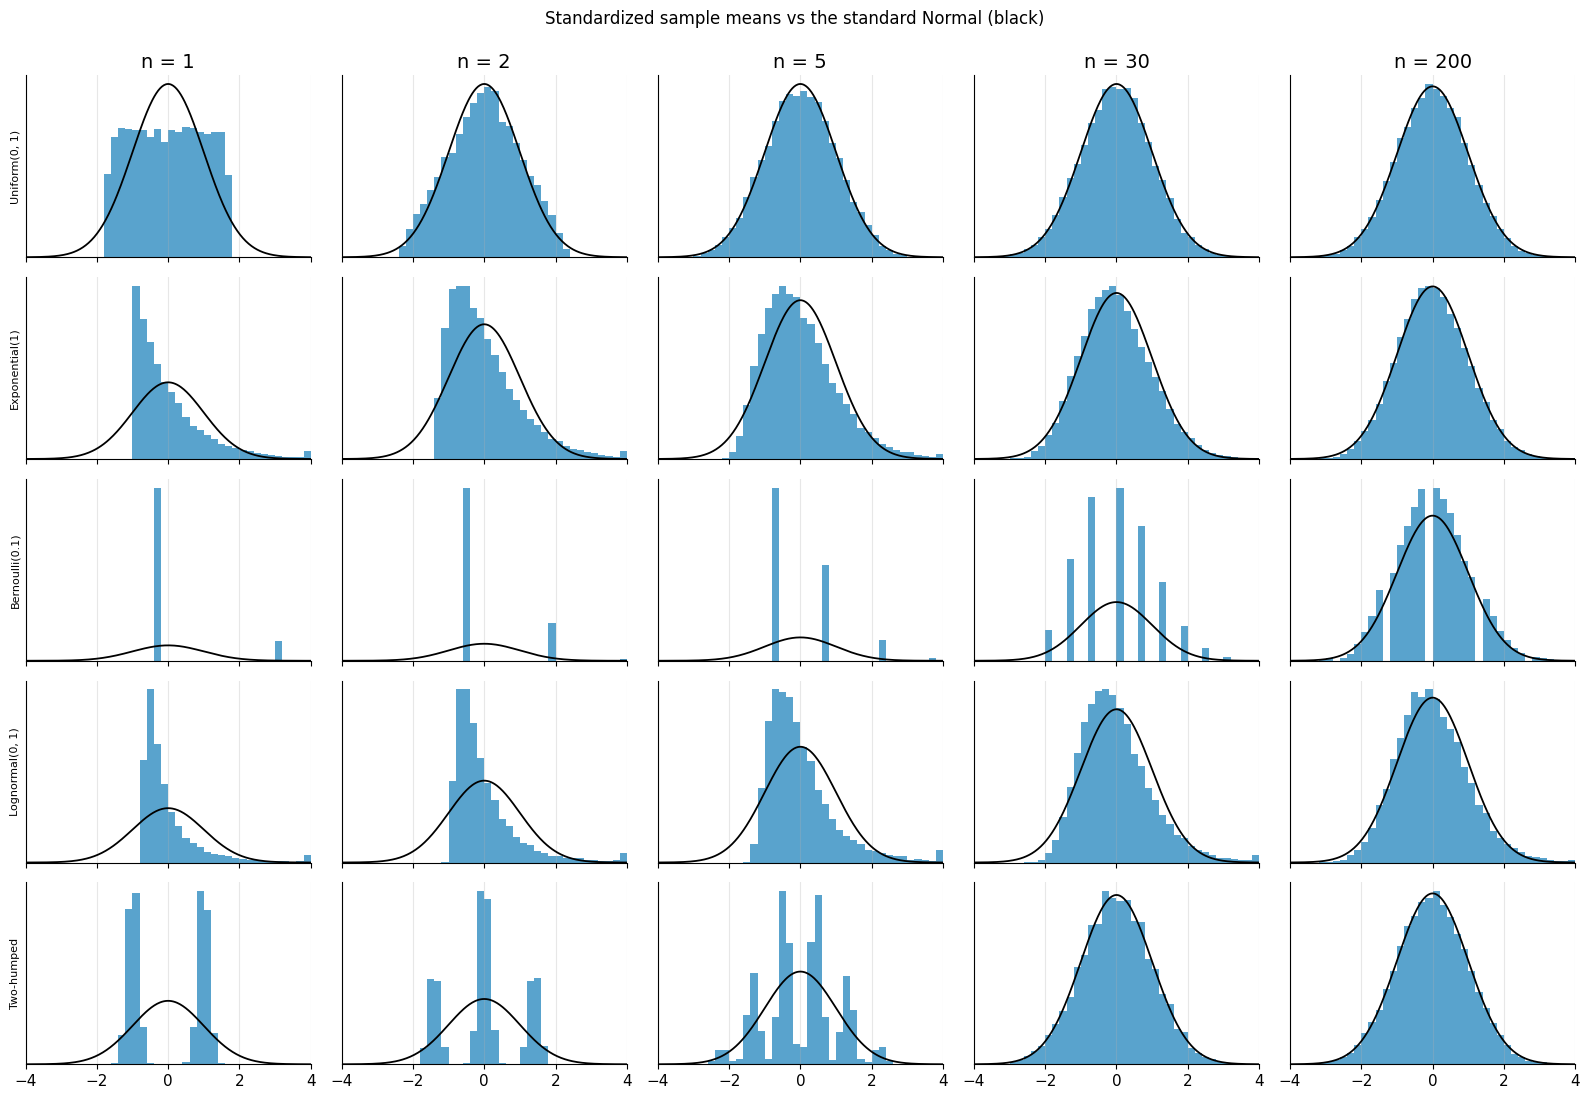

In [2]:
parents = {
    "Uniform(0, 1)": (lambda size: rng.uniform(0, 1, size), 0.5, np.sqrt(1 / 12)),
    "Exponential(1)": (lambda size: rng.exponential(1, size), 1.0, 1.0),
    "Bernoulli(0.1)": (lambda size: rng.binomial(1, 0.1, size), 0.1, np.sqrt(0.09)),
    "Lognormal(0, 1)": (lambda size: rng.lognormal(0, 1, size), np.exp(0.5), np.sqrt((np.e - 1) * np.e)),
    "Two-humped (50/50 mix of N(0, 0.3), N(4, 0.3))": (lambda size: np.where(rng.random(size) < 0.5, rng.normal(0, 0.3, size), rng.normal(4, 0.3, size)), 2.0, np.sqrt(0.09 + 4)),
}
sizes = [1, 2, 5, 30, 200]
fig, axes = plt.subplots(len(parents), len(sizes), figsize=(16, 11), sharex=True)
zz = np.linspace(-4, 4, 300)
for r, (name, (sampler, mu, sd)) in enumerate(parents.items()):
    for c, n in enumerate(sizes):
        z = (sampler((20000, n)).mean(axis=1) - mu) / (sd / np.sqrt(n))
        axes[r, c].hist(np.clip(z, -4, 4), bins=40, range=(-4, 4), density=True, color=MAIN, alpha=0.65)
        axes[r, c].plot(zz, stats.norm.pdf(zz), "k", linewidth=1.3)
        if r == 0: axes[r, c].set_title(f"n = {n}")
        if c == 0: axes[r, c].set_ylabel(name.split(" (")[0], fontsize=8)
        axes[r, c].set_xlim(-4, 4); axes[r, c].set_yticks([])
fig.suptitle("Standardized sample means vs the standard Normal (black)", y=0.995)
plt.tight_layout()
plt.show()

### 7.2 Q-Q plots: how Normal is it, in the tails?
A Q-Q plot compares the sample quantiles with Normal quantiles; points on the line mean Normal. For the Exponential parent, the points hug the line at n = 30 but still bend in the right tail at n = 5; for the Lognormal(0, 1) parent even n = 200 is visibly curved in the tail.

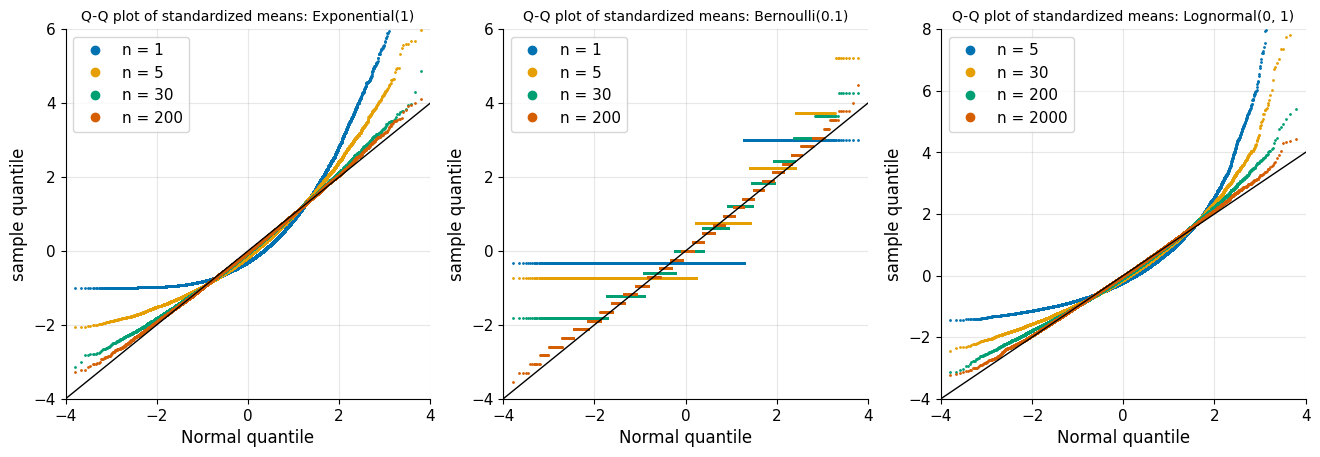

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, n_list) in zip(axes, [("Exponential(1)", [1, 5, 30, 200]), ("Bernoulli(0.1)", [1, 5, 30, 200]), ("Lognormal(0, 1)", [5, 30, 200, 2000])]):
    sampler, mu, sd = parents[name]
    for n, color in zip(n_list, COLORS):
        z = np.sort((sampler((20000, n)).mean(axis=1) - mu) / (sd / np.sqrt(n)))
        q = stats.norm.ppf((np.arange(1, z.size + 1) - 0.5) / z.size)
        ax.plot(q, z, ".", markersize=2, color=color, label=f"n = {n}")
    ax.plot([-4, 4], [-4, 4], "k", linewidth=1)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 8 if "Lognormal" in name else 6)
    ax.set_title(f"Q-Q plot of standardized means: {name}", fontsize=10)
    ax.set_xlabel("Normal quantile"); ax.set_ylabel("sample quantile")
    ax.legend(markerscale=6)
plt.show()

### 7.3 How fast? Kolmogorov distance versus n, for different skewness
Gamma($k$) parents have skewness $2/\sqrt k$ and their means are exactly Gamma($nk$), so the distance to the Normal can be computed without simulation. The error follows $\propto\gamma/\sqrt n$: the more skewed the parent, the longer the wait.

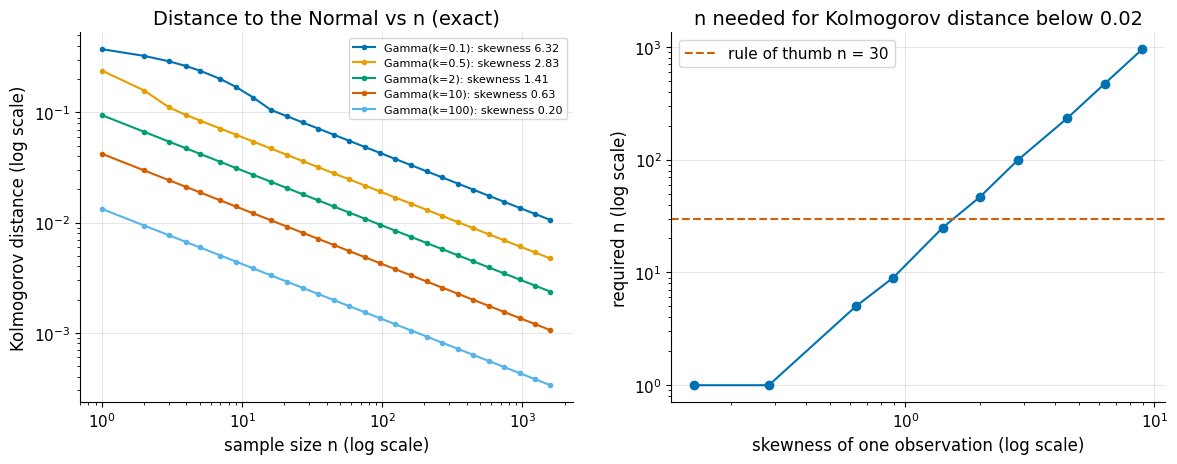

skewness -> n needed: [(8.94, 952), (6.32, 472), (4.47, 233), (2.83, 99), (2.0, 47), (1.41, 25), (0.89, 9), (0.63, 5), (0.28, 1), (0.14, 1)]


In [4]:
def kolmogorov_gamma_parent(k, n):
    """Distance between the standardized mean of n Gamma(k) draws and N(0, 1), computed exactly (the mean is Gamma(n k, scale 1/n))."""
    mu, sd = k, np.sqrt(k)
    z = np.linspace(-6, 6, 4001)
    x = mu + z * sd / np.sqrt(n)
    return np.max(np.abs(stats.gamma(a=n * k, scale=1 / n).cdf(x) - stats.norm.cdf(z)))

n_axis = np.unique(np.logspace(0, 3.2, 30).astype(int))
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8))
for k, color in zip([0.1, 0.5, 2, 10, 100], COLORS):
    errors = [kolmogorov_gamma_parent(k, n) for n in n_axis]
    ax_a.loglog(n_axis, errors, "o-", markersize=3, color=color, label=f"Gamma(k={k}): skewness {2 / np.sqrt(k):.2f}")
ax_a.set_title("Distance to the Normal vs n (exact)")
ax_a.set_xlabel("sample size n (log scale)"); ax_a.set_ylabel("Kolmogorov distance (log scale)")
ax_a.legend(fontsize=8)
target = 0.02
needed = []
skews = []
for k in [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 50, 200]:
    n = 1
    while kolmogorov_gamma_parent(k, n) > target and n < 100000:
        n = int(n * 1.15) + 1
    needed.append(n); skews.append(2 / np.sqrt(k))
ax_b.loglog(skews, needed, "o-", color=MAIN)
ax_b.axhline(30, color=HIGHLIGHT, linestyle="--", label="rule of thumb n = 30")
ax_b.set_title("n needed for Kolmogorov distance below 0.02")
ax_b.set_xlabel("skewness of one observation (log scale)"); ax_b.set_ylabel("required n (log scale)")
ax_b.legend()
plt.show()
print("skewness -> n needed:", [(round(float(s), 2), int(n)) for s, n in zip(skews, needed)])

### 7.4 The first-order Edgeworth correction fixes most of the skew error
For the Exponential parent at n = 10: exact distribution of the standardized mean, the plain Normal, and the Normal with the skewness correction $-\frac{\gamma}{6\sqrt n}(z^2-1)\varphi(z)$.

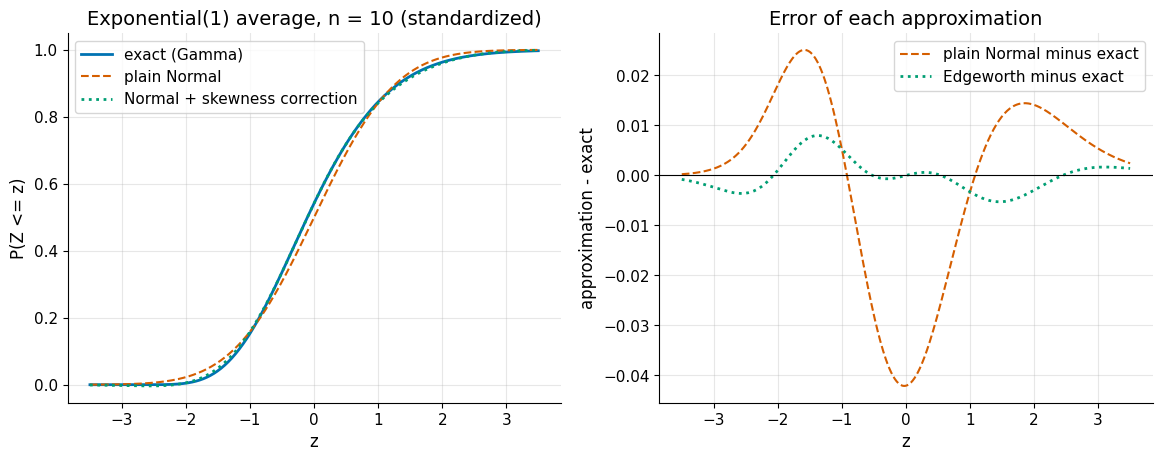

largest absolute error: plain Normal 0.0421 | with correction 0.008


In [5]:
n, k = 10, 1
z = np.linspace(-3.5, 3.5, 500)
exact_cdf = stats.gamma(a=n * k, scale=1 / n).cdf(k + z * np.sqrt(k) / np.sqrt(n))
gamma_skew = 2 / np.sqrt(k)
edgeworth = stats.norm.cdf(z) - gamma_skew / (6 * np.sqrt(n)) * (z**2 - 1) * stats.norm.pdf(z)
fig, (ax_cdf, ax_err) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_cdf.plot(z, exact_cdf, color=MAIN, linewidth=2, label="exact (Gamma)")
ax_cdf.plot(z, stats.norm.cdf(z), "--", color=HIGHLIGHT, label="plain Normal")
ax_cdf.plot(z, edgeworth, ":", color=COLORS[2], linewidth=2, label="Normal + skewness correction")
ax_cdf.set_title("Exponential(1) average, n = 10 (standardized)")
ax_cdf.set_xlabel("z"); ax_cdf.set_ylabel("P(Z <= z)"); ax_cdf.legend()
ax_err.plot(z, stats.norm.cdf(z) - exact_cdf, "--", color=HIGHLIGHT, label="plain Normal minus exact")
ax_err.plot(z, edgeworth - exact_cdf, ":", color=COLORS[2], linewidth=2, label="Edgeworth minus exact")
ax_err.axhline(0, color="black", linewidth=0.8)
ax_err.set_title("Error of each approximation")
ax_err.set_xlabel("z"); ax_err.set_ylabel("approximation - exact"); ax_err.legend()
plt.show()
print("largest absolute error: plain Normal", round(float(np.max(np.abs(stats.norm.cdf(z) - exact_cdf))), 4), "| with correction", round(float(np.max(np.abs(edgeworth - exact_cdf))), 4))

### 7.5 When the CLT fails: infinite variance
For Pareto parents the standardized average does not become Normal if $\alpha\le2$ (infinite variance): at $\alpha=1.2$ the histogram stays spiky and one-sided however large $n$ is; at $\alpha=3$ (finite variance) it behaves.

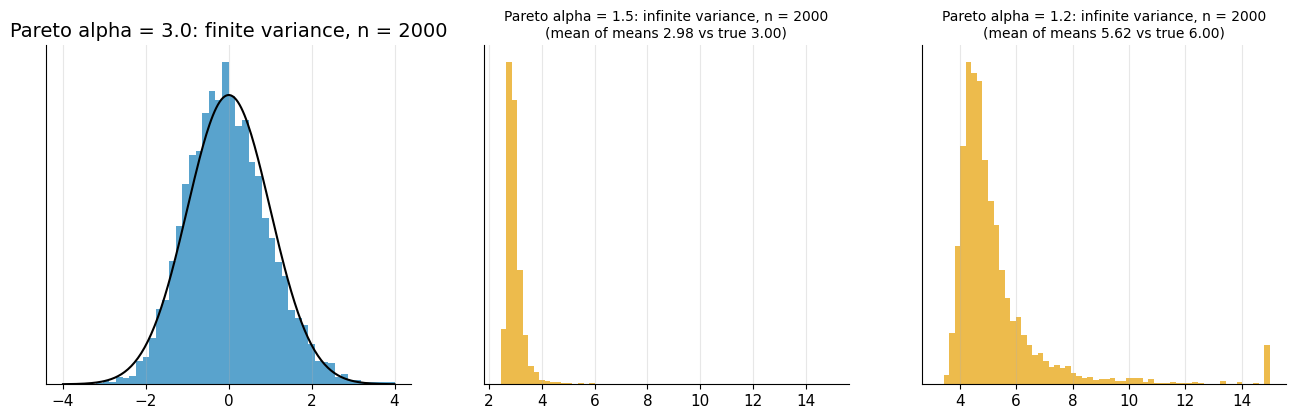

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, alpha in zip(axes, [3.0, 1.5, 1.2]):
    n = 2000
    means = (rng.pareto(alpha, (5000, n)) + 1).mean(axis=1)
    mu = alpha / (alpha - 1)
    if alpha > 2:
        sd = np.sqrt(alpha / ((alpha - 1) ** 2 * (alpha - 2)))
        z = (means - mu) / (sd / np.sqrt(n))
        ax.hist(np.clip(z, -4, 4), bins=50, range=(-4, 4), density=True, color=MAIN, alpha=0.65)
        ax.plot(np.linspace(-4, 4, 200), stats.norm.pdf(np.linspace(-4, 4, 200)), "k")
        ax.set_title(f"Pareto alpha = {alpha}: finite variance, n = {n}")
    else:
        ax.hist(np.clip(means, 0, 15), bins=60, density=True, color=SIM, alpha=0.7)
        ax.set_title(f"Pareto alpha = {alpha}: infinite variance, n = {n}\n(mean of means {means.mean():.2f} vs true {mu:.2f})", fontsize=10)
    ax.set_yticks([])
plt.show()

## 8. 3D visuals

### 8.1 Static: the density of the standardized mean as n grows
For an Exponential(1) parent the standardized mean has an exact density (Gamma). The surface shows the density over $(n,z)$: a skewed ridge at small $n$ that settles into the Normal bell. The Normal bell is the flat 'end state' at large $n$.

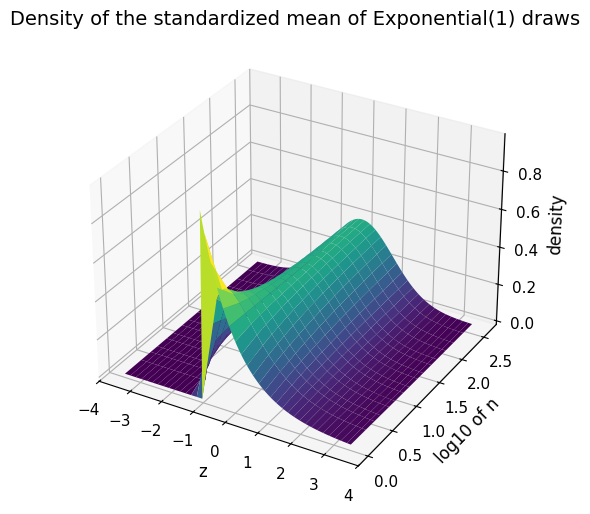

peak of the density: n = 1 -> 0.971 , n = 400 -> 0.399  (Normal peak 0.399 )


In [7]:
z_axis = np.linspace(-3.5, 3.5, 120)
n_axis3 = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 100, 150, 250, 400])
def std_mean_density(n, z):
    # standardized mean of Exponential(1): Z = sqrt(n) (mean - 1), mean ~ Gamma(n, scale 1/n)
    return stats.gamma(a=n, scale=1 / n).pdf(1 + z / np.sqrt(n)) / np.sqrt(n)
D = np.array([std_mean_density(n, z_axis) for n in n_axis3])
Zg, Ng = np.meshgrid(z_axis, np.log10(n_axis3))
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Zg, Ng, D, cmap="viridis", edgecolor="none")
ax.set_title("Density of the standardized mean of Exponential(1) draws")
ax.set_xlabel("z"); ax.set_ylabel("log10 of n"); ax.set_zlabel("density")
ax.view_init(elev=30, azim=-60)
plt.show()
print("peak of the density: n = 1 ->", round(float(D[0].max()), 3), ", n = 400 ->", round(float(D[-1].max()), 3), " (Normal peak", round(float(stats.norm.pdf(0)), 3), ")")

### 8.2 Static: the error as a function of both n and the parent's skewness
Exact Kolmogorov distance for Gamma($k$) parents over a grid of $n$ and skewness $2/\sqrt k$. The valley floor is the symmetric case; the ridge at small $n$ and high skewness is where the CLT is not yet useful.

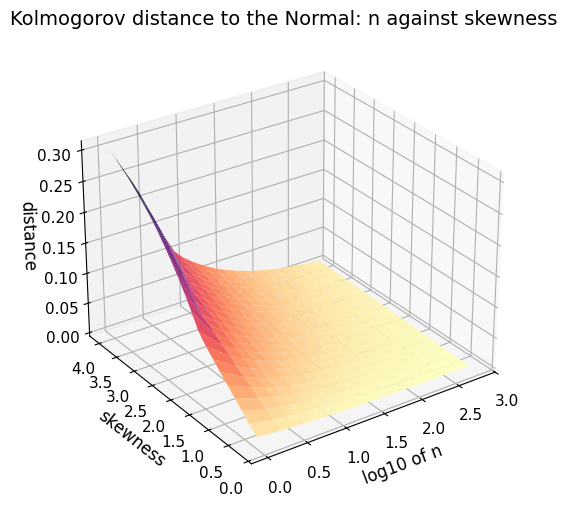

In [8]:
n_grid = np.unique(np.logspace(0, 2.8, 22).astype(int))
skew_grid = np.linspace(0.2, 4.0, 22)
E = np.array([[kolmogorov_gamma_parent(4 / s**2, n) for n in n_grid] for s in skew_grid])
Ng2, Sg2 = np.meshgrid(np.log10(n_grid), skew_grid)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng2, Sg2, E, cmap="magma_r", edgecolor="none")
ax.set_title("Kolmogorov distance to the Normal: n against skewness")
ax.set_xlabel("log10 of n"); ax.set_ylabel("skewness"); ax.set_zlabel("distance")
ax.view_init(elev=28, azim=-125)
plt.show()

### 8.3 Interactive Plotly version of 8.2
Rotate and hover to read the distance for any combination.

In [9]:
fig = go.Figure(go.Surface(x=n_grid, y=skew_grid, z=E, colorscale="Magma", reversescale=True))
fig.update_layout(title="Distance to the Normal vs n and parent skewness", width=750, height=550,
                  scene=dict(xaxis_title="n", yaxis_title="skewness", zaxis_title="Kolmogorov distance", xaxis_type="log"))
fig.show()

## 9. Simulation vs theory

### 9.1 Mean, standard deviation and skewness of the sample mean
Three predictions of the CLT picture, checked on the Exponential(1) parent: the mean of $\bar X_n$ is $\mu$, the standard deviation is $\sigma/\sqrt n$, and the skewness is $\gamma/\sqrt n$ (here $2/\sqrt n$).

In [10]:
rows = []
for n in [2, 8, 32, 128, 512]:
    means = rng.exponential(1, (100_000, n)).mean(axis=1)
    rows.append({"n": n, "mean (theory 1)": means.mean(), "sd (theory)": means.std(), "sigma/sqrt(n)": 1 / np.sqrt(n),
                 "skewness": stats.skew(means), "gamma/sqrt(n)": 2 / np.sqrt(n)})
table = pd.DataFrame(rows)
print(table.round(4).to_string(index=False))
assert np.allclose(table["mean (theory 1)"], 1, atol=0.01)
assert np.allclose(table["sd (theory)"], table["sigma/sqrt(n)"], rtol=0.02)
assert np.allclose(table["skewness"], table["gamma/sqrt(n)"], rtol=0.12)

  n  mean (theory 1)  sd (theory)  sigma/sqrt(n)  skewness  gamma/sqrt(n)
  2           1.0002       0.7053         0.7071    1.3966         1.4142
  8           0.9994       0.3519         0.3536    0.6693         0.7071
 32           1.0007       0.1768         0.1768    0.3400         0.3536
128           1.0000       0.0882         0.0884    0.1765         0.1768
512           1.0004       0.0442         0.0442    0.0919         0.0884


### 9.2 Kolmogorov distance: simulation against the exact value
Simulated standardized means from 200,000 samples against the exact distance for Exponential(1): they agree up to the simulation noise floor of about 0.002.

In [11]:
rows = []
for n in [1, 3, 10, 30, 100]:
    z = np.sort((rng.exponential(1, (200_000, n)).mean(axis=1) - 1) * np.sqrt(n))
    ecdf_hi = np.arange(1, z.size + 1) / z.size
    ecdf_lo = np.arange(0, z.size) / z.size
    sim = max(np.max(np.abs(ecdf_hi - stats.norm.cdf(z))), np.max(np.abs(ecdf_lo - stats.norm.cdf(z))))
    rows.append({"n": n, "simulated distance": sim, "exact distance": kolmogorov_gamma_parent(1, n)})
cmp = pd.DataFrame(rows)
print(cmp.round(4).to_string(index=False))
assert np.allclose(cmp["simulated distance"], cmp["exact distance"], atol=0.004)

  n  simulated distance  exact distance
  1              0.1587          0.1582
  3              0.0761          0.0771
 10              0.0431          0.0421
 30              0.0245          0.0243
100              0.0132          0.0133


## 10. `scipy.stats` cheat sheet for this lesson

In [12]:
n, mu, sigma = 50, 85.0, 60.0
approx = stats.norm(loc=n * mu, scale=sigma * np.sqrt(n))            # sum of n orders
print("P(total of 50 orders > 4500) by the CLT:", round(approx.sf(4500), 4))
print("central 95 % range of the total:", np.round(approx.interval(0.95), 1))
mean_model = stats.norm(loc=mu, scale=sigma / np.sqrt(n))             # average order value
print("P(average within 10 of mu):", round(mean_model.cdf(mu + 10) - mean_model.cdf(mu - 10), 4))
print("standardizing: z = (xbar - mu) / (sigma / sqrt(n)); for xbar = 95:", round((95 - mu) / (sigma / np.sqrt(n)), 3))
print("skewness and excess kurtosis of a sample: stats.skew, stats.kurtosis ->", round(stats.skew(rng.exponential(1, 5000)), 2), round(stats.kurtosis(rng.exponential(1, 5000)), 2))
print("normality test (stats.normaltest) on 5000 standardized means of 5 Exponential draws rejects Normality:", bool(stats.normaltest((rng.exponential(1, (5000, 5)).mean(axis=1) - 1) * np.sqrt(5)).pvalue < 0.05))

P(total of 50 orders > 4500) by the CLT: 0.2778
central 95 % range of the total: [3418.5 5081.5]
P(average within 10 of mu): 0.7614
standardizing: z = (xbar - mu) / (sigma / sqrt(n)); for xbar = 95: 1.179
skewness and excess kurtosis of a sample: stats.skew, stats.kurtosis -> 1.95 5.1
normality test (stats.normaltest) on 5000 standardized means of 5 Exponential draws rejects Normality: True


## 11. Real-world worked examples

---
### Example 1 (main): the daily sales total of an online shop

**Scenario (illustrative numbers).** A shop receives **60 orders per day**. Order values are skewed (many small, a few large) with mean **\$85** and standard deviation **\$60**; they are well described by a **Lognormal** distribution. Orders are independent. The daily revenue is $S=\sum_{i=1}^{60}X_i$.

**Questions**
1. What are the mean and standard deviation of the daily revenue $S$?
2. By the CLT, what is $P(S>5{,}500)$? Compare with the simulated truth and with the skewness-corrected (Edgeworth) value.
3. Give a central 95 % range for the daily revenue.
4. How many orders are needed so that the **average order value** is within **\$5** of the true mean with 95 % confidence?

### 11.1 By hand
**Q1.** $E[S]=n\mu=60\cdot85=\$5{,}100$; $\mathrm{Var}(S)=n\sigma^2=60\cdot3600=216{,}000$, so $\mathrm{sd}(S)=\sqrt{216000}=\$464.76$.

**Q2.** $z=\dfrac{5500-5100}{464.76}=0.861$, so $P(S>5500)\approx1-\Phi(0.861)=0.1946$. (The Lognormal parent has skewness $\gamma=\sqrt{e^{s^2}-1}\,(e^{s^2}+2)$ with $s^2=\ln(1+(60/85)^2)=0.4047$; the Edgeworth correction adds $\frac{\gamma}{6\sqrt n}(z^2-1)\varphi(z)$ to the upper tail with the sign worked out in code.)

**Q3.** $5100\pm1.96\cdot464.76=5100\pm911$, i.e. **\$4,189 to \$6,011**.

**Q4.** Need $1.96\cdot\dfrac{60}{\sqrt n}\le5\Rightarrow\sqrt n\ge23.52\Rightarrow n\ge553.2$, so **$n=554$** orders.

In [13]:
import math

n_orders, mean_order, sd_order = 60, 85.0, 60.0
mean_total = n_orders * mean_order
sd_total = math.sqrt(n_orders) * sd_order
print(f"Q1: mean {mean_total:.1f}, standard deviation {sd_total:.2f}")

def standard_normal_cdf(z):
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))
def standard_normal_pdf(z):
    return math.exp(-z * z / 2) / math.sqrt(2 * math.pi)

z_threshold = (5500 - mean_total) / sd_total
p_clt = 1 - standard_normal_cdf(z_threshold)
s2 = math.log(1 + (sd_order / mean_order) ** 2)                       # lognormal sigma^2 of the underlying Normal
skew_parent = math.sqrt(math.exp(s2) - 1) * (math.exp(s2) + 2)
edgeworth_upper = p_clt + skew_parent / (6 * math.sqrt(n_orders)) * (z_threshold**2 - 1) * standard_normal_pdf(z_threshold)
print(f"Q2: z = {z_threshold:.3f}; P(S > 5500) by the CLT = {p_clt:.4f}; parent skewness {skew_parent:.3f}; with the skewness correction {edgeworth_upper:.4f}")
low, high = mean_total - 1.959964 * sd_total, mean_total + 1.959964 * sd_total
print(f"Q3: central 95 % range: {low:.0f} to {high:.0f}")
n_needed = math.ceil((1.959964 * sd_order / 5) ** 2)
print(f"Q4: orders needed for +/- $5 on the average order value: {n_needed}")

Q1: mean 5100.0, standard deviation 464.76
Q2: z = 0.861; P(S > 5500) by the CLT = 0.1947; parent skewness 2.469; with the skewness correction 0.1909
Q3: central 95 % range: 4189 to 6011
Q4: orders needed for +/- $5 on the average order value: 554


### 11.2 In code with `scipy`, and the asserts

In [14]:
s_norm = np.sqrt(np.log(1 + (sd_order / mean_order) ** 2))
m_norm = np.log(mean_order) - s_norm**2 / 2
order = stats.lognorm(s=s_norm, scale=np.exp(m_norm))                  # Lognormal with mean 85 and sd 60
assert np.isclose(order.mean(), mean_order) and np.isclose(order.std(), sd_order)
total_clt = stats.norm(n_orders * order.mean(), np.sqrt(n_orders) * order.std())
assert np.isclose(total_clt.sf(5500), p_clt)
assert np.allclose(total_clt.interval(0.95), (low, high), atol=0.5)
assert n_needed == int(np.ceil((stats.norm.isf(0.025) * order.std() / 5) ** 2))
print("order value: mean", round(order.mean(), 2), "sd", round(order.std(), 2), "skewness", round(float(order.stats(moments='s')), 3))

order value: mean 85.0 sd 60.0 skewness 2.469


### 11.3 Verify by simulation

In [15]:
totals = order.rvs(size=(400_000, n_orders), random_state=11).sum(axis=1)
print(f"simulation: mean {totals.mean():.1f}, sd {totals.std():.2f}")
print(f"P(S > 5500): CLT {p_clt:.4f} | with skewness correction {edgeworth_upper:.4f} | simulated {np.mean(totals > 5500):.4f}")
print(f"central 95 % range from simulation: {np.percentile(totals, 2.5):.0f} to {np.percentile(totals, 97.5):.0f} (CLT: {low:.0f} to {high:.0f})")
print(f"coverage of the CLT range: {np.mean((totals >= low) & (totals <= high)):.4f}")
assert abs(totals.mean() - mean_total) < 3 and abs(totals.std() - sd_total) < 3
sim_means = order.rvs(size=(100_000, n_needed), random_state=12).mean(axis=1)
print(f"Q4 check: with n = {n_needed} the average order is within $5 of 85 in {np.mean(np.abs(sim_means - mean_order) <= 5):.4f} of days (target 0.95)")

simulation: mean 5100.0, sd 464.78
P(S > 5500): CLT 0.1947 | with skewness correction 0.1909 | simulated 0.1902
central 95 % range from simulation: 4261 to 6079 (CLT: 4189 to 6011)
coverage of the CLT range: 0.9515


Q4 check: with n = 554 the average order is within $5 of 85 in 0.9518 of days (target 0.95)


### 11.4 Plots with the regions shaded

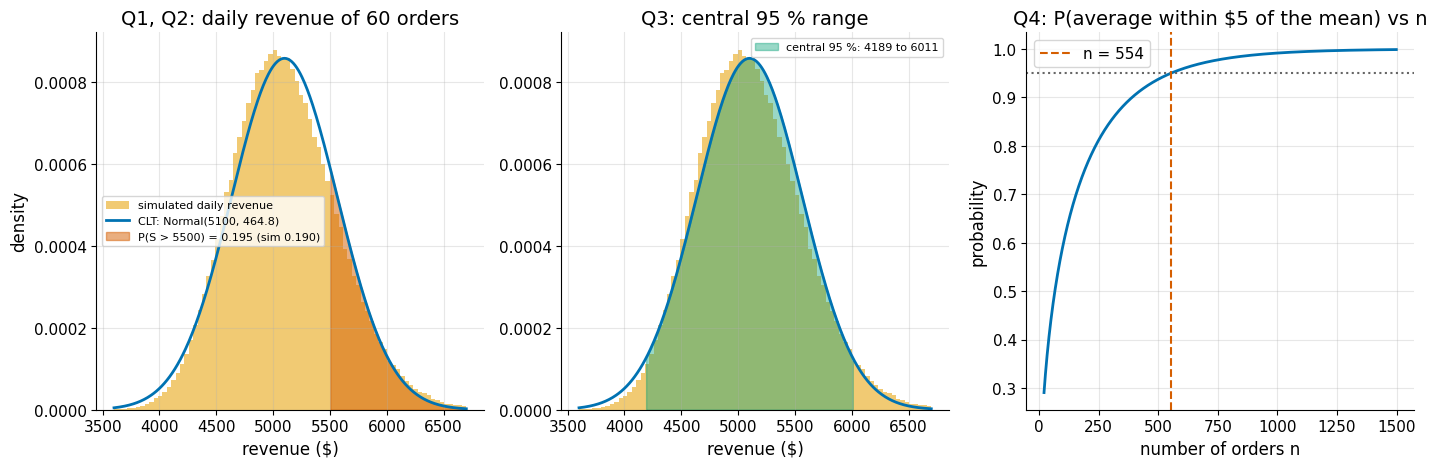

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
x = np.linspace(3600, 6700, 400)
axes[0].hist(totals, bins=80, range=(3600, 6700), density=True, color=SIM, alpha=0.55, label="simulated daily revenue")
axes[0].plot(x, total_clt.pdf(x), color=MAIN, linewidth=2, label="CLT: Normal(5100, 464.8)")
axes[0].fill_between(x[x > 5500], total_clt.pdf(x[x > 5500]), color=HIGHLIGHT, alpha=0.5, label=f"P(S > 5500) = {p_clt:.3f} (sim {np.mean(totals > 5500):.3f})")
axes[0].set_title("Q1, Q2: daily revenue of 60 orders")
axes[0].set_xlabel("revenue ($)"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
axes[1].hist(totals, bins=80, range=(3600, 6700), density=True, color=SIM, alpha=0.55)
axes[1].plot(x, total_clt.pdf(x), color=MAIN, linewidth=2)
inside = (x >= low) & (x <= high)
axes[1].fill_between(x[inside], total_clt.pdf(x[inside]), color=COLORS[2], alpha=0.4, label=f"central 95 %: {low:.0f} to {high:.0f}")
axes[1].set_title("Q3: central 95 % range")
axes[1].set_xlabel("revenue ($)"); axes[1].legend(fontsize=8)
ns = np.arange(20, 1500)
axes[2].plot(ns, 2 * stats.norm.cdf(5 * np.sqrt(ns) / sd_order) - 1, color=MAIN, linewidth=2)
axes[2].axhline(0.95, color=NEUTRAL, linestyle=":")
axes[2].axvline(n_needed, color=HIGHLIGHT, linestyle="--", label=f"n = {n_needed}")
axes[2].set_title("Q4: P(average within $5 of the mean) vs n")
axes[2].set_xlabel("number of orders n"); axes[2].set_ylabel("probability"); axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
See the printed numbers above. In words:
- Expected daily revenue is **\$5,100** with a typical day-to-day swing of **about \$465**. The CLT gives a **19.5 %** chance of a day above \$5,500; the simulation (which uses the true Lognormal orders) gives **19.0 %**, and the skewness-corrected value (19.1 %) is closer: the right-skewed parent makes very high totals slightly *less* likely than the symmetric Normal says.
- The central 95 % range of revenue is **\$4,190 to \$6,010** by the CLT; the simulated range is **\$4,261 to \$6,079**, shifted up by about \$70 because of the skew, yet the CLT range still captures 95.2 % of days. Plan staffing and cash for that range, not just for the mean.
- To pin down the **average order value** to within \$5 you need about **554 orders**: that is nine days of data at 60 orders per day; to be within \$2.50 you would need four times as many (about 2,200).
- **Decision:** the CLT is accurate here because the daily total adds 60 orders and the skewness of the *total* is only $\gamma/\sqrt{60}$ (about 0.4 for this parent). Use the CLT for the daily total; do **not** use it for a single order (very skewed).

---
### Example 2: a control chart for bottle filling (CLT with a non-Normal parent)

**Scenario (illustrative).** A filling machine puts $X$ ml in each bottle; the fill amount is **Uniform** between 495 and 505 ml (mean 500, SD 2.887). Every hour an inspector weighs **n = 5** bottles and plots the mean. A Shewhart chart signals an alarm when the mean is outside $\mu\pm3\sigma/\sqrt n$. How often does a false alarm occur, and does the Normal assumption matter?

**By hand.** $\sigma/\sqrt n=2.887/\sqrt5=1.291$, so the limits are $500\pm3.873$, i.e. **496.13 to 503.87**. Under the Normal approximation the false alarm probability is $2(1-\Phi(3))=0.00270$ per hour, an average of $1/0.0027=370$ hours between false alarms. The exact distribution of the mean of 5 Uniform draws is the (scaled) Irwin-Hall distribution; we compute it by simulation and by exact convolution.

In [17]:
n_bottles = 5
mu_fill, sd_fill = 500.0, 10 / math.sqrt(12)
limit = 3 * sd_fill / math.sqrt(n_bottles)
print(f"limits: {mu_fill - limit:.2f} to {mu_fill + limit:.2f}; Normal-based false alarm probability {2 * (1 - standard_normal_cdf(3)):.5f} (one alarm per {1 / (2 * (1 - standard_normal_cdf(3))):.0f} hours)")
# exact false alarm probability: sum of n Uniform(0,1) is Irwin-Hall; P(S <= s) = (1/n!) sum_k (-1)^k C(n,k) (s - k)^n for s in [0, n]
def irwin_hall_cdf(s, n):
    return sum((-1) ** k * math.comb(n, k) * max(s - k, 0) ** n for k in range(n + 1)) / math.factorial(n)
low_u = (mu_fill - limit - 495) / 10 * n_bottles                      # lower limit as a sum of n Uniform(0, 1)
high_u = (mu_fill + limit - 495) / 10 * n_bottles
exact_alarm = irwin_hall_cdf(low_u, n_bottles) + 1 - irwin_hall_cdf(high_u, n_bottles)
sim_alarm = np.mean(np.abs(rng.uniform(495, 505, (2_000_000, n_bottles)).mean(axis=1) - 500) > limit)
print(f"exact false-alarm probability {exact_alarm:.5f} | simulated {sim_alarm:.5f} | Normal approximation 0.00270")
assert abs(sim_alarm - exact_alarm) < 0.0004
print(f"average run length between false alarms: exact {1 / exact_alarm:.0f} hours vs CLT {1 / 0.0026998:.0f}")

limits: 496.13 to 503.87; Normal-based false alarm probability 0.00270 (one alarm per 370 hours)
exact false-alarm probability 0.00095 | simulated 0.00096 | Normal approximation 0.00270
average run length between false alarms: exact 1056 hours vs CLT 370


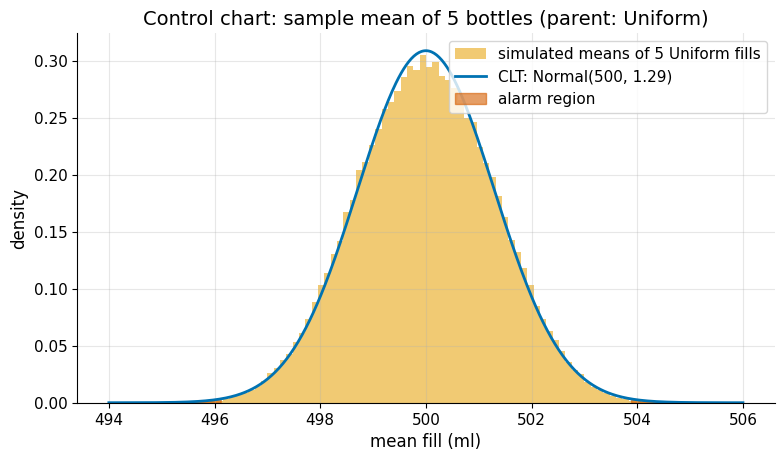

In [18]:
x = np.linspace(494, 506, 500)
means = rng.uniform(495, 505, (200_000, n_bottles)).mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(means, bins=100, range=(494, 506), density=True, color=SIM, alpha=0.55, label="simulated means of 5 Uniform fills")
ax.plot(x, stats.norm(500, sd_fill / np.sqrt(n_bottles)).pdf(x), color=MAIN, linewidth=2, label="CLT: Normal(500, 1.29)")
for side, region in (("lower", x < 500 - limit), ("upper", x > 500 + limit)):
    ax.fill_between(x[region], stats.norm(500, sd_fill / np.sqrt(n_bottles)).pdf(x[region]), color=HIGHLIGHT, alpha=0.6, label="alarm region" if side == "lower" else None)
ax.set_title("Control chart: sample mean of 5 bottles (parent: Uniform)")
ax.set_xlabel("mean fill (ml)"); ax.set_ylabel("density"); ax.legend()
plt.show()

**Interpretation.** With a flat parent and only **n = 5** the distribution of the mean is already bell-shaped, but the *tails* are not Normal: the exact false-alarm probability is **0.095 %** (one alarm every 1,056 hours), about **three times lower** than the CLT's 0.27 % (one every 370 hours). The mean of 5 bounded Uniform values simply cannot go as far out as a Normal can, so the Normal approximation overestimates the tail. **Decision:** the 3-sigma limits are safe (fewer false alarms than advertised) but slightly insensitive; for a bounded parent you may tighten the limits using the exact distribution. Do not use the same limits for individual bottles (a flat parent never exceeds 3 sigma, so those limits would never signal). The lesson: the CLT is reliable in the centre, and the tails converge last.

---
### Example 3: the CLT fails quietly: revenue per user with heavy skew

**Scenario (illustrative).** In an A/B test the revenue per user is extremely skewed: most users spend nothing or little, a few spend a lot (Lognormal with $s=2$, mean about 7.4, SD about 54). An analyst builds the 95 % confidence interval $\bar x\pm1.96\,s/\sqrt n$. Question: **how often does this interval contain the true mean**, for $n=30,100,1000,10000$?

**By hand.** The parent skewness is $\gamma=\sqrt{e^{4}-1}(e^{4}+2)\approx414$, so the CLT error term $\gamma/\sqrt n$ is enormous until $n$ is in the hundreds of thousands: the rule $n\ge30$ does not apply. We measure the coverage by simulation.

In [19]:
s_heavy = 2.0
heavy = stats.lognorm(s=s_heavy, scale=1.0)
true_mean = heavy.mean()
print(f"true mean {true_mean:.3f}, sd {heavy.std():.2f}, skewness {float(heavy.stats(moments='s')):.0f}")
rows = []
local = np.random.default_rng(2024)
for n in (30, 100, 1000, 10000):
    reps = 20000 if n <= 1000 else 4000
    data = local.lognormal(0, s_heavy, (reps, n))
    xbar = data.mean(axis=1)
    se = data.std(axis=1, ddof=1) / np.sqrt(n)
    covered = np.mean(np.abs(xbar - true_mean) <= 1.96 * se)
    rows.append({"n": n, "coverage of the 95 % interval": covered, "share of intervals missing low": np.mean(xbar + 1.96 * se < true_mean), "share missing high": np.mean(xbar - 1.96 * se > true_mean)})
coverage_table = pd.DataFrame(rows)
print(coverage_table.round(4).to_string(index=False))
assert coverage_table["coverage of the 95 % interval"].iloc[0] < 0.75
assert coverage_table["coverage of the 95 % interval"].is_monotonic_increasing

true mean 7.389, sd 54.10, skewness 414


    n  coverage of the 95 % interval  share of intervals missing low  share missing high
   30                         0.6462                          0.3537              0.0000
  100                         0.7400                          0.2598              0.0001
 1000                         0.8541                          0.1450              0.0009
10000                         0.9160                          0.0820              0.0020


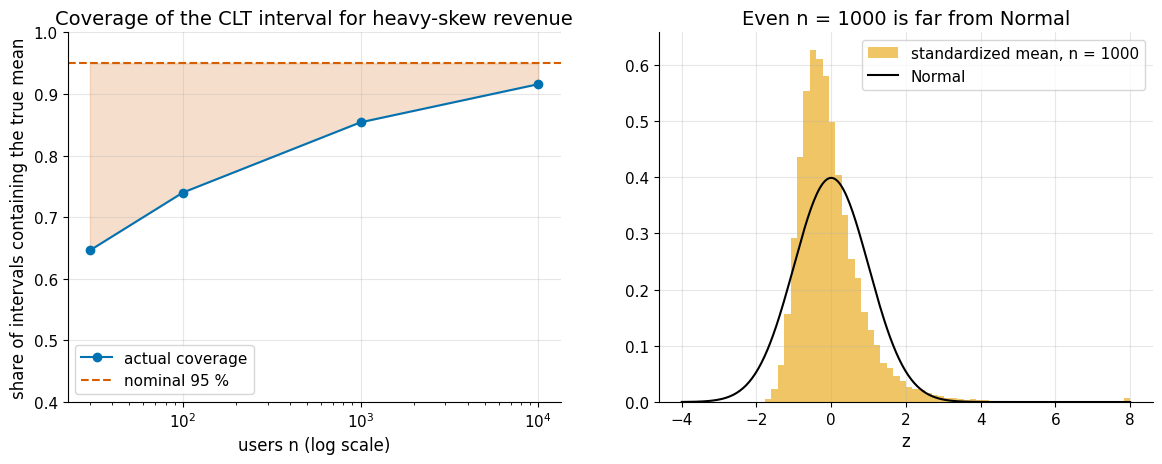

share of z above 2 at n = 1000: 0.0297 (Normal: 0.0228); share below -2: 0.0 (Normal: 0.0228)


In [20]:
fig, (ax_cov, ax_hist) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_cov.semilogx(coverage_table["n"], coverage_table["coverage of the 95 % interval"], "o-", color=MAIN, label="actual coverage")
ax_cov.axhline(0.95, color=HIGHLIGHT, linestyle="--", label="nominal 95 %")
ax_cov.fill_between(coverage_table["n"], coverage_table["coverage of the 95 % interval"], 0.95, color=HIGHLIGHT, alpha=0.2)
ax_cov.set_ylim(0.4, 1)
ax_cov.set_title("Coverage of the CLT interval for heavy-skew revenue")
ax_cov.set_xlabel("users n (log scale)"); ax_cov.set_ylabel("share of intervals containing the true mean"); ax_cov.legend()
z = (local.lognormal(0, s_heavy, (20000, 1000)).mean(axis=1) - true_mean) / (heavy.std() / np.sqrt(1000))
ax_hist.hist(np.clip(z, -4, 8), bins=70, range=(-4, 8), density=True, color=SIM, alpha=0.6, label="standardized mean, n = 1000")
ax_hist.plot(np.linspace(-4, 8, 300), stats.norm.pdf(np.linspace(-4, 8, 300)), "k", label="Normal")
ax_hist.set_title("Even n = 1000 is far from Normal")
ax_hist.set_xlabel("z"); ax_hist.legend()
plt.show()
print("share of z above 2 at n = 1000:", round(float(np.mean(z > 2)), 4), "(Normal: 0.0228); share below -2:", round(float(np.mean(z < -2)), 4), "(Normal: 0.0228)")

**Interpretation.** With heavy skew the 95 % interval covers the truth **far less than 95 %** of the time at small and moderate $n$ (the table above), and it fails almost always on the *same side*: the sample mean is usually below the true mean (most samples miss the rare big spenders), so the interval is shifted. The coverage creeps toward 95 % only for $n$ in the thousands. **Decision:** for skewed money metrics do not trust $n\ge30$; use a **bootstrap** (05_04), analyse a transformed metric (log or capped revenue), or use very large samples, and always check the skewness of the data before applying a CLT-based interval.

## 12. Where it is used

### Statistics
- **Confidence intervals and z/t tests** for means and proportions; the Wald interval is a direct CLT statement.
- **Control charts, sampling plans and polling margins of error** (Example 2); asymptotic distributions of maximum-likelihood estimators.

### Data science
- **A/B testing** and monitoring: the test statistic is a standardized difference of means whose Normal shape comes from the CLT; sample-size planning uses $z\sigma/\varepsilon$ (05_01).
- **Aggregated metrics:** daily revenue, total latency, error counts are sums of many small contributions and are approximately Normal (Example 1).

### ML and AI
- **Stochastic gradient noise** is approximately Gaussian by the CLT (mini-batch averages), which motivates SGD-as-diffusion analyses.
- **Wide neural networks at initialization** behave like Gaussian processes because pre-activations are sums of many independent terms; Gaussian approximations of posteriors (Laplace) rest on the same idea.

## 13. Common pitfalls and misconceptions

- **"The data become Normal":** no; it is the *distribution of the sum or average* that becomes Normal. Individual observations keep their own shape however many you collect.
- **The $n\ge30$ rule is not a law:** it is fine for mild skew (Exponential) but fails for heavy skew (Example 3) and is overkill for symmetric parents (Example 2).
- **Infinite variance breaks the CLT:** Cauchy, Pareto with alpha at most 2, some financial returns. Averages then follow stable laws, not Normals.
- **Dependence:** the CLT needs (nearly) independent summands, or a corrected variance (time series, clustered data).
- **Tails converge last:** the Normal fits the centre first; probabilities of extreme events (Example 1's 5,500 threshold sits only 0.9 sigma out, but a 5-sigma event would be poorly approximated).
- **Discrete variables:** use the continuity correction (04_02).
- **Standardize with the right standard deviation:** for an average divide by $\sigma/\sqrt n$, for a sum by $\sigma\sqrt n$; do not mix them.

## 14. Exercises

1. The weight of a parcel has mean 12 kg and standard deviation 5 kg. A van carries 100 parcels. Find the probability that the total exceeds 1,250 kg and the weight limit exceeded only 1 % of the time (the 99th percentile of the total).
2. A fair die is rolled 100 times. Approximate the probability that the sum is between 330 and 370 (inclusive). Compare with the exact value (compute by convolution).
3. Using Berry-Esseen with $\rho/\sigma^3$ for a Bernoulli($p$), find the smallest $n$ for which the *guaranteed* Kolmogorov error is below 0.05 when $p=0.5$; compare it with the real (much smaller) error you compute.
4. The average of 40 iid Exponential(2) waiting times (mean 2 minutes) is used for a decision. Find $P(\bar X>2.5)$ by the CLT and exactly (Gamma). Which is larger?
5. Simulate the 95 % interval coverage for the Exponential(1) parent with $n=5,10,30,100$ (use the sample standard deviation). When does it reach 94 %?
6. (Harder) Show with the MGF argument why a *symmetric* parent has an error of order $1/n$ rather than $1/\sqrt n$ (hint: the cubic term vanishes).

Solutions are at the end.

## 15. Summary table

| Item | Statement | Condition | Remark |
|---|---|---|---|
| CLT for averages | (average - mu) / (sigma / sqrt n) tends to N(0, 1) | iid, finite variance | only mean and variance of the parent matter |
| CLT for sums | sum approx N(n mu, n sigma^2) | same | |
| Speed | Kolmogorov error at most 0.4748 rho / (sigma^3 sqrt n) | finite third moment | driven by skewness |
| First correction | minus gamma / (6 sqrt n) (z^2 - 1) pdf(z) | skewness gamma | Edgeworth expansion |
| Symmetric parent | error of order 1 / n | skewness 0 | n = 5 to 10 often enough |
| Heavy skew | n in the thousands | skewness large | check coverage, use bootstrap |
| Failure | stable laws, no Normal limit | infinite variance | Cauchy, Pareto alpha at most 2 |

## Solutions

In [21]:
n, mu, sd = 100, 12.0, 5.0
total = stats.norm(n * mu, sd * np.sqrt(n))
print("1: P(total > 1250) =", round(total.sf(1250), 4), "; 99th percentile =", round(total.ppf(0.99), 1), "kg")
die = np.ones(6) / 6
dist = np.array([1.0])
for _ in range(100):
    dist = np.convolve(dist, np.r_[0, die])                              # exact distribution of the sum of 100 dice (index = sum)
sums = np.arange(dist.size)
exact2 = dist[(sums >= 330) & (sums <= 370)].sum()
approx2 = stats.norm(350, np.sqrt(100 * 35 / 12)).cdf(370.5) - stats.norm(350, np.sqrt(100 * 35 / 12)).cdf(329.5)
print("2: exact", round(exact2, 4), " CLT with continuity correction", round(approx2, 4))
n3 = 1
while 0.4748 * 1 / np.sqrt(n3) > 0.05:                                    # for p = 0.5: rho / sigma^3 = (p^2 + (1-p)^2) / sqrt(p (1-p)) = 1
    n3 += 1
print("3: guaranteed error below 0.05 needs n =", n3, "; real corrected error at that n:", round(float(np.max(np.abs(stats.binom.cdf(np.arange(n3 + 1), n3, 0.5) - stats.norm.cdf(np.arange(n3 + 1) + 0.5, n3 / 2, np.sqrt(n3 / 4))))), 5))
clt4 = stats.norm(2, 2 / np.sqrt(40)).sf(2.5)
exact4 = stats.gamma(a=40, scale=2 / 40).sf(2.5)
print("4: CLT", round(clt4, 4), " exact", round(exact4, 4), "(the exact right tail is larger: the mean is right-skewed)")
local = np.random.default_rng(5)
for n5 in (5, 10, 30, 100):
    x = local.exponential(1, (20000, n5)); xb = x.mean(axis=1); se = x.std(axis=1, ddof=1) / np.sqrt(n5)
    print("5: n =", n5, " coverage", round(float(np.mean(np.abs(xb - 1) <= 1.96 * se)), 4))

1: P(total > 1250) = 0.1587 ; 99th percentile = 1316.3 kg
2: exact 0.7697  CLT with continuity correction 0.77
3: guaranteed error below 0.05 needs n = 91 ; real corrected error at that n: 0.0003
4: CLT 0.0569  exact 0.0646 (the exact right tail is larger: the mean is right-skewed)
5: n = 5  coverage 0.8078
5: n = 10  coverage 0.8645
5: n = 30  coverage 0.9179
5: n = 100  coverage 0.9384


**1.** Total mean 1,200 and SD 50, so $P(S>1250)=1-\Phi(1)=0.1587$ and the 99th percentile is $1200+2.326\cdot50=1316$ kg.

**2.** The exact probability and the continuity-corrected CLT value (printed) agree to about three decimals: the die is symmetric, so $n=100$ is more than enough.

**3.** For $p=0.5$, $\rho/\sigma^3=1$, so the guarantee is $0.4748/\sqrt n<0.05$, which needs $n\ge91$; the real corrected error at that $n$ is about 0.0003, over a hundred times smaller: Berry-Esseen is a safe, very pessimistic bound.

**4.** The CLT gives 0.0569 and the exact Gamma tail is 0.0646, larger because the mean of Exponentials is right-skewed (its upper tail is heavier than the Normal's).

**5.** Coverage rises slowly: about 81 % at n = 5, 86 % at n = 10, 92 % at n = 30 and 93.8 % at n = 100 (printed). It only reaches 94 % just beyond n = 100, so for a skewed parent the "n = 30" rule is optimistic even for the standard interval.

**6.** For a symmetric parent $\gamma=0$ and the expansion of $\ln M_{Z_n}(t)$ is $\frac{t^2}2+\frac{\kappa_4t^4}{24n}+\dots$ (no $t^3$ term), so the leading error is of order $1/n$.